# Generate the data

In [1]:
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from amp import MSE, norm_sq_corr, PAL, hausdorff
from amp.marginal_separable_jax import q, GAMP_full, SE_fixed_C_v1, GAMP_gaussian_clean, SE_fixed_C, GAMP
import amp.marginal_separable_jax
import amp.changepoint_jax as changepoint_jax
import amp.signal_configuration
from amp.signal_configuration import C_to_chgpt, generate_C_distanced, unif_prior_to_η_ϕ
from amp.signal_priors import SignalPrior, SparseDiffSignal, SparseGaussianSignal, GaussianSignal
from amp.posterior import MAP, MAP_η, compute_posterior, posterior_over_η, η_to_ψ
from amp.marginal_separable_jax import GAMP_gaussian_clean, GAMP_real_data, q
from amp.signal_priors import GaussianSignal
from functools import partial
from tqdm import tqdm
import scipy
tqdm = partial(tqdm, position=0, leave=True)
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn import linear_model
import scipy

# np.random.seed(1)

p = 500
σ = 0.1 # noise standard deviation
L = 2 # num signals. L-1 changepoints

T = 2 # num_iterations
δ_list = [0.5, 0.75, 1.0, 1.25, 1.5, 1.75, 2.0]

chgpt_location = 0.4


In [2]:
### Define a function that finds the optimal changepoint location given z = Xβ and y
def opt_chgpt_gof(z_1, z_2, y, η_arr):

    m = np.inf
    for i in range(len(η_arr)): 
        η = η_arr[i]
        gof = (((z_1 - y)**2)[:η[0]].sum() + ((z_2 - y)**2)[η[0]:].sum()) / y.shape[0]
        if gof < m:
            m = gof
            η_opt = η
            i_opt = i
    return η_opt, i_opt

# Run Weighted ERM (preliminary)

  0%|          | 0/7 [00:00<?, ?it/s]

δ =  0.5
True chgpts = 100


  0%|          | 0/2 [00:00<?, ?it/s]

/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 6.462e-04, tolerance: 4.610e-04
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.256e-03, tolerance: 4.610e-04
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regula

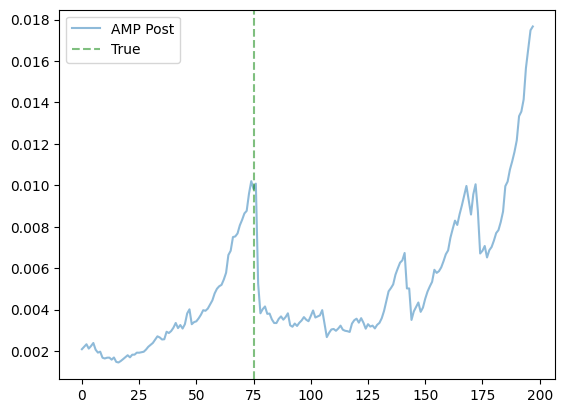

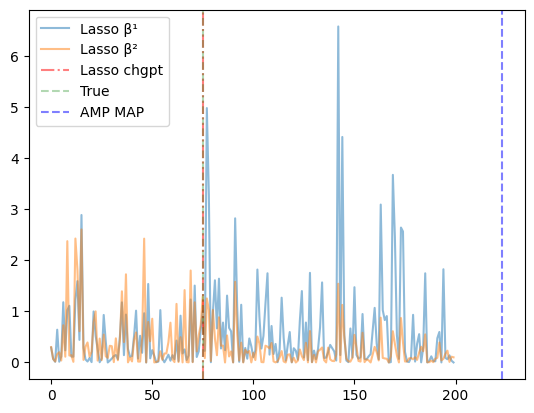

 14%|█▍        | 1/7 [00:58<05:52, 58.68s/it]

δ =  0.75
True chgpts = 150


  0%|          | 0/2 [00:00<?, ?it/s]

/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.491e-03, tolerance: 6.833e-04
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.710e-03, tolerance: 6.833e-04
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regula

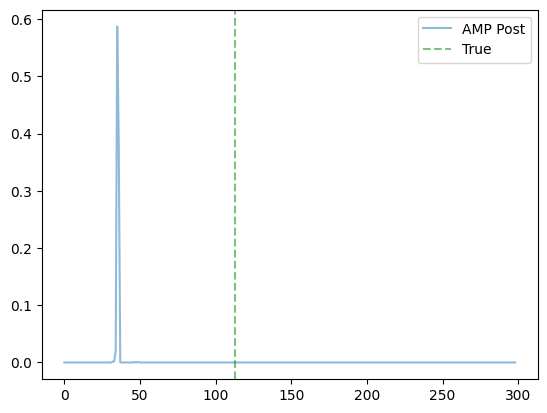

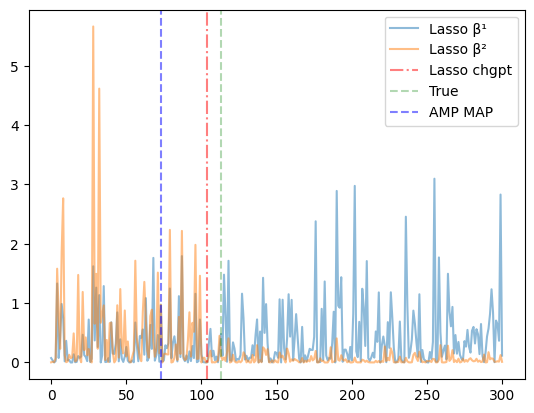

 29%|██▊       | 2/7 [02:20<06:02, 72.49s/it]

δ =  1.0
True chgpts = 200


  0%|          | 0/2 [00:00<?, ?it/s]

/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.649e-03, tolerance: 1.826e-03
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.565e-03, tolerance: 1.985e-03
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regula

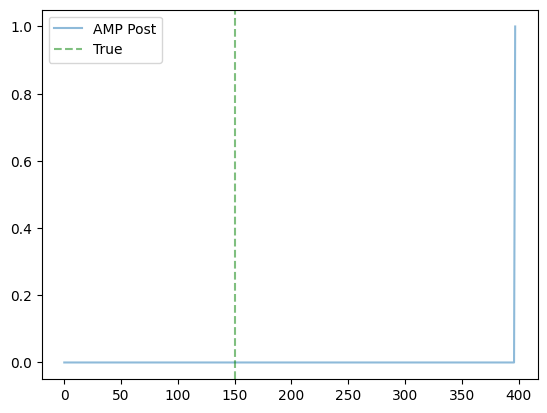

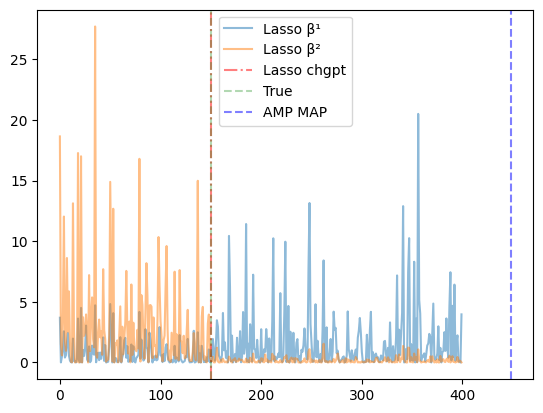

 43%|████▎     | 3/7 [03:48<05:18, 79.63s/it]

δ =  1.25
True chgpts = 250


  0%|          | 0/2 [00:00<?, ?it/s]

/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.019e-02, tolerance: 1.669e-03
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.295e-02, tolerance: 1.669e-03
  model = cd_fast.enet_coordinate_descent(
/Users/gabrielarpino/.local/lib/python3.10/site-packages/sklearn/linear_model/_coordinate_descent.py:628: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regula

KeyboardInterrupt: 

In [3]:
corr_1_list = []
corr_2_list = []
corr_1_SE_list = []
corr_2_SE_list = []
post_list = []
lasso_haus_list = []
AMP_haus_list = []
lasso_corr_1_list = []
lasso_corr_2_list = []


for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    true_chgpt_locations = lambda n: int(n*chgpt_location)

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/10)
    Lmin = 2
    Lmax = 2
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    print(f"True chgpts = {true_chgpt_locations(n)}")
    C_true = η_to_ψ(np.array([true_chgpt_locations(n)]), n)

    # Soft threshold denoiser 
    σ_l_arr = np.array([2.5, 2.5]) # signal standard deviation
    α = 0.5 # fraction of nonzeros
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)
    st_ζ = 0.5 # The scaling factor in front of the effective noise std in the threshold
    # if soft thresholding. Setting st_ζ != None in the GAMP_full function.

    B̃ = signal_prior.sample(p)
    B̂_0 = signal_prior.sample(p)

    # ρ = 1/δ * B̃_cov # 1/δ * Covariance matrix of each row of B_0, independent for now but should be generalized later
    ρ = 1/δ * 1/p * B̃.T @ B̃

    # Generate a covariance matrix
    # Identity covariance
    # Σ = np.eye(p)
    # Generate a reasonable covariance matrix
    # Σ = np.zeros((p, p))
    # for i in range(p):
    #     for j in range(p):
    #         Σ[i, j] = 0.75 ** (np.abs(i - j))
    # Another random covariance construction: 
    A = np.random.rand(p, p)
    Σ = np.dot(A, A.transpose()) / p

    L_chol = scipy.linalg.cholesky(Σ, lower = True)
    #Σ = L_chol @ L_chol.T

    # Generate the observation vector Y
    # X = np.random.normal(0, np.sqrt(1/n), (n, p))
    X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T
    Θ = X @ B̃
    Y = q(Θ, C_true, σ) 

    B̂, Θ_t, ν_arr, κ_T_arr, ν̂_arr, κ_B_arr, ν_fixed_arr, κ_T_fixed_arr, ν̂_fixed_arr, κ_B_fixed_arr = GAMP_full(B̃, δ, p, ϕ, σ, X, Y, C_true, T, B̂_0, signal_prior, signal_prior, st_ζ = st_ζ, verbose = False, seed = None, tqdm_disable = False)
    # # B̂, Θ_t, ν_arr, κ_T_arr, ν̂_arr, κ_B_arr = GAMP(B̃, δ, p, ϕ, σ, X, Y, T, true_signal_prior=signal_prior, est_signal_prior=signal_prior)
    ν = ν_arr[-1]
    κ_T = κ_T_arr[-1]
    ν_fixed = ν_fixed_arr[-1]
    κ_T_fixed = κ_T_fixed_arr[-1]


    # Run Weighted ERM
    # Weight data for \beta^1, ϕ is L × n
    Y_weighted_1 = (Y.flatten() * np.sqrt(ϕ[0, :]).flatten()).reshape(-1, 1) # Element-wise multiplication
    X_weighted_1 = X * np.sqrt(ϕ[0, :]).reshape(-1, 1) # Element-wise multiplication
    lasso_cv = linear_model.LassoCV(cv=5, n_jobs=2, tol=1e-5)
    lasso_cv.fit(X_weighted_1, Y_weighted_1.flatten())
    lasso_1 = linear_model.Lasso(alpha=lasso_cv.alpha_, tol=1e-12, max_iter=int(1e5))
    lasso_1.fit(X_weighted_1, Y_weighted_1.flatten())
    β̂_1 = lasso_1.coef_

    # Run weighted ERM for \beta^2
    Y_weighted_2 = (Y.flatten() * np.sqrt(ϕ[1, :]).flatten()).reshape(-1, 1) # Element-wise multiplication
    X_weighted_2 = X * np.sqrt(ϕ[1, :]).reshape(-1, 1) # Element-wise multiplication
    lasso_cv = linear_model.LassoCV(cv=5, n_jobs=2, tol=1e-5)
    lasso_cv.fit(X_weighted_2, Y_weighted_2.flatten())
    lasso_2 = linear_model.Lasso(alpha=lasso_cv.alpha_, tol=1e-12, max_iter=int(1e5))
    lasso_2.fit(X_weighted_2, Y_weighted_2.flatten())
    β̂_2 = lasso_2.coef_

    # Append results for Weighted Lasso ERM
    lasso_corr_1_list.append(norm_sq_corr(β̂_1, B̃[:, 0]))
    lasso_corr_2_list.append(norm_sq_corr(β̂_2, B̃[:, 1]))

    # Append results for AMP
    corr_1_list.append(norm_sq_corr(B̂[:, 0], B̃[:, 0]))
    corr_2_list.append(norm_sq_corr(B̂[:, 1], B̃[:, 1]))
    corr_1_SE_list.append(ν_fixed[0, 0]**2 / ( ρ[0, 0] * (κ_T_fixed + ν_fixed.T @ np.linalg.inv(ρ) @ ν_fixed)[0, 0]))
    corr_2_SE_list.append(ν_fixed[1, 1]**2 / ( ρ[1, 1] * (κ_T_fixed + ν_fixed.T @ np.linalg.inv(ρ) @ ν_fixed)[1, 1]))

    ## Compute posterior for AMP, and MAP estimate
    post_Θ_Y = amp.posterior.posterior_over_η(η_arr, p_η_arr, Θ_t, Y, ρ, σ, ν, κ_T)
    plt.plot(post_Θ_Y, alpha = 0.5, label="AMP Post")
    plt.axvline(x=true_chgpt_locations(n) - Δ(n) , color='g', linestyle='--', alpha = 0.5, label="True")
    plt.legend()
    plt.show()
    post_list.append(post_Θ_Y)
    AMP_η_MAP = amp.posterior.MAP_η(η_arr, post_Θ_Y)
    # AMP_η_MAP = np.array([1, *amp.posterior.MAP_η(η_arr, post_Θ_Y), n]) # add 1 and n to the beginning and end
    # AMP_η_MAP = AMP_η_MAP[AMP_η_MAP != -1]
    AMP_haus_list.append((1/n) * amp.performance_measures.hausdorff(AMP_η_MAP, true_chgpt_locations(n)))

    ## Compute MAP estimate for lasso
    plt.plot(((Y.flatten() - X @ β̂_1)**2)[Δ(n): n - Δ(n)], alpha = 0.5, label="Lasso β¹")
    plt.plot(((Y.flatten() - X @ β̂_2)**2)[Δ(n): n - Δ(n)], alpha = 0.5, label="Lasso β²")
    opt_chgpt_loc, opt_chgpt_idx = opt_chgpt_gof(X @ β̂_1, X @ β̂_2, Y.flatten(), η_arr)
    # plot a vertical line at the optimal changepoint location
    plt.axvline(x=opt_chgpt_idx, color='r', linestyle='-.', alpha = 0.5, label="Lasso chgpt")
    plt.axvline(x=true_chgpt_locations(n) - Δ(n) , color='g', linestyle='--', alpha = 0.3, label="True")
    plt.axvline(x=AMP_η_MAP, color='b', linestyle='--', alpha = 0.5, label="AMP MAP")
    plt.legend()
    plt.show()
    lasso_haus_list.append(1/n * hausdorff(opt_chgpt_loc, true_chgpt_locations(n)))

# Sqcorr plots
plt.errorbar(δ_list, (lasso_corr_1_list), label="Lasso β¹", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, (lasso_corr_2_list), label="Lasso β²", marker="o", ls="-.", c=PAL[3], alpha = 1.0)
plt.errorbar(δ_list, (corr_1_list), label="AMP β¹", marker="o", ls="--", c=PAL[0], alpha = 1.0)
plt.errorbar(δ_list, (corr_2_list), label="AMP β²", marker="o", ls="--", c=PAL[2], alpha = 1.0)
plt.scatter(δ_list,corr_1_SE_list, label="Theory", marker="x", alpha = 1.0, c=PAL[0])
plt.scatter(δ_list, corr_2_SE_list, label="Theory", marker="x", alpha = 1.0, c=PAL[2])
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# Lin reg + Covariance: WERM

  0%|          | 0/4 [00:00<?, ?it/s]

δ =  0.5
True chgpts = [75]
Regressing on signal  0
Regressing on signal  1
Regressing on signal  2


100%|██████████| 15077/15077 [00:01<00:00, 11478.98it/s]


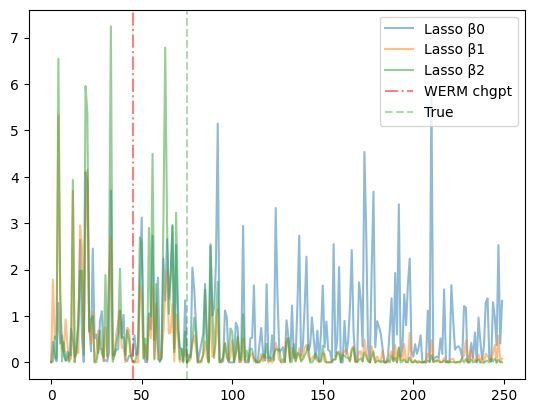

 25%|██▌       | 1/4 [00:39<01:57, 39.07s/it]

δ =  1.0
True chgpts = [150]
Regressing on signal  0
Regressing on signal  1
Regressing on signal  2


100%|██████████| 60777/60777 [00:05<00:00, 11441.74it/s]


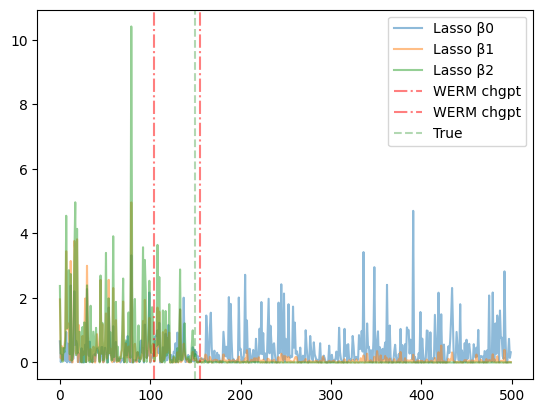

 50%|█████     | 2/4 [02:08<02:17, 68.96s/it]

δ =  1.5
True chgpts = [225]
Regressing on signal  0
Regressing on signal  1
Regressing on signal  2


100%|██████████| 137102/137102 [00:12<00:00, 11328.16it/s]


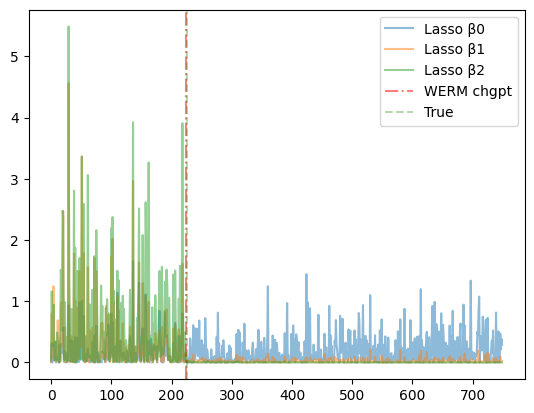

 75%|███████▌  | 3/4 [02:41<00:52, 52.43s/it]

δ =  2.0
True chgpts = [300]
Regressing on signal  0
Regressing on signal  1
Regressing on signal  2


100%|██████████| 244052/244052 [00:21<00:00, 11141.69it/s]


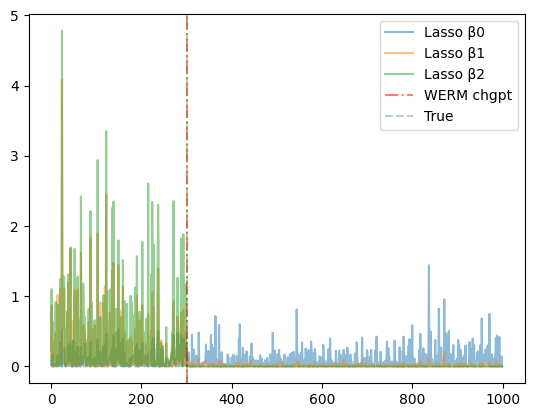

100%|██████████| 4/4 [03:19<00:00, 49.90s/it]


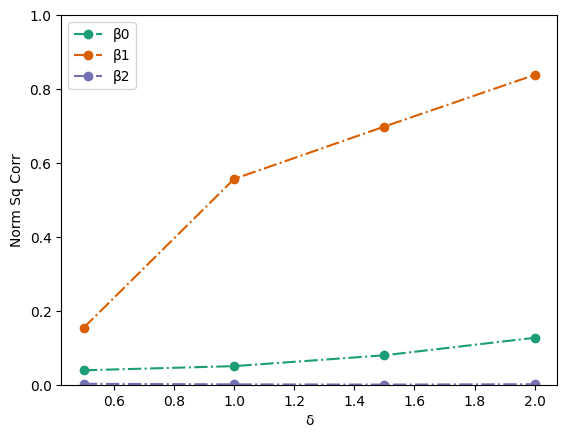

In [3]:
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from amp import MSE, norm_sq_corr, PAL, hausdorff
from amp.marginal_separable_jax import q
import amp.marginal_separable_jax
import amp.changepoint_jax as changepoint_jax
import amp.signal_configuration
from amp.signal_configuration import C_to_chgpt, generate_C_distanced, unif_prior_to_η_ϕ
from amp.signal_priors import SignalPrior, SparseDiffSignal, SparseGaussianSignal, GaussianSignal
from amp.posterior import MAP, MAP_η, compute_posterior, posterior_over_η, η_to_ψ
from amp.marginal_separable_jax import GAMP_gaussian_clean, GAMP_real_data, q
from amp.signal_priors import GaussianSignal
import amp.comparison
from functools import partial
from tqdm import tqdm
import scipy
tqdm = partial(tqdm, position=0, leave=True)
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn import linear_model
import scipy
from WERM.gof import η_arr_to_C_s

# Remove sklearn warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

# np.random.seed(1)

p = 500
σ = 0.1 # noise standard deviation
L = 3 # num signals. L-1 changepoints

δ_list = [0.5, 1.0, 1.5, 2.0]

# chgpt_locations = np.array([0.3, 0.7])
chgpt_locations = np.array([0.3])

### Define a function that finds the optimal changepoint location given z = Xβ and y
def opt_chgpt_gof(Z, y, η_arr, p_η_arr):
    """ Z is n × L, where L is the number of signals. """

    C_s = η_arr_to_C_s(η_arr, Z.shape[0])  
    # C_s = η_to_ψ_jax_mapped(η_arr, Z.shape[0])

    m = np.inf
    for i in tqdm(range(len(C_s))): 
        ψ = C_s[i]
        # gof = np.linalg.norm(y - Z[np.arange(Z.shape[0]), ψ], ord=2)**2 / y.shape[0]
        gof = np.linalg.norm(y - Z[np.arange(Z.shape[0]), ψ], ord=2)**2 / (2 * σ**2) - np.log(p_η_arr[i])
        if gof < m:
            m = gof
            η_opt = η_arr[i]
            i_opt = i
    return η_opt[η_opt != -1], i_opt

corr_1_list = []
corr_2_list = []
corr_1_SE_list = []
corr_2_SE_list = []
post_list = []
WERM_haus_list = []
WERM_size_list = []
NWERM_haus_list = []
DCDP_haus_list = []
AMP_haus_list = []
lasso_corr_list = [[] for ℓ in range(L)]

# Generate a covariance matrix
# Identity covariance
# Σ = np.eye(p)
# Generate a reasonable covariance matrix
Σ = np.zeros((p, p))
for i in range(p):
    for j in range(p):
        Σ[i, j] = 0.5 ** (np.abs(i - j))
# Another random covariance construction: 
# A_ = np.random.rand(p, p)
# Σ = np.dot(A_, A_.transpose()) / p

L_chol = scipy.linalg.cholesky(Σ, lower = True)

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    true_chgpt_locations = lambda n: (n*chgpt_locations).astype(int)

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/10)
    Lmin = 1
    Lmax = L
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    # p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    print(f"True chgpts = {true_chgpt_locations(n)}")
    C_true = η_to_ψ(true_chgpt_locations(n), n)

    #  Sparse Gaussian prior
    σ_l_arr = 1.0 * np.ones(L) # signal standard deviation
    α = 0.5 # fraction of nonzeros
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # Gaussian signal prior
    # κ = 1.0
    # B̃_cov = κ**2 * δ * np.eye(L) # keeps the signal power fixed
    # signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)

    # Generate the observation vector Y
    # X = np.random.normal(0, np.sqrt(1/n), (n, p))
    X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T
    Θ = X @ B̃
    Y = q(Θ, C_true, σ) 

    # --- Run Weighted ERM --- #

    B̂ = np.zeros((p, L))
    for ℓ in range(L):
        print("Regressing on signal ", ℓ)
        # Weight data for \beta^1, ϕ is L × n
        Y_weighted = (Y.flatten() * np.sqrt(ϕ[ℓ, :]).flatten()).reshape(-1, 1) # Element-wise multiplication
        X_weighted = X * np.sqrt(ϕ[ℓ, :]).reshape(-1, 1) # Element-wise multiplication
        lasso_cv = linear_model.LassoCV(cv=5, n_jobs=2, tol=1e-5)
        lasso_cv.fit(X_weighted, Y_weighted.flatten())
        lasso = linear_model.Lasso(alpha=lasso_cv.alpha_, tol=1e-12, max_iter=int(1e5))
        lasso.fit(X_weighted, Y_weighted.flatten())
        β̂ = lasso.coef_

        # standard least squares
        # sample_weight = ϕ[ℓ, :]
        # sk_lin_reg = linear_model.LinearRegression(n_jobs = 2, fit_intercept = False)
        # sk_lin_reg.fit(X, Y, sample_weight = sample_weight)
        # β̂ = sk_lin_reg.coef_


        B̂[:, ℓ] = β̂
        lasso_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))

    ## Compute MAP estimate for WERM
    for ℓ in range(L):
        plt.plot(((Y.flatten() - X @ B̂[:, ℓ])**2), alpha = 0.5, label="Lasso β" + str(ℓ))
    Z = X @ B̂
    opt_chgpt_loc, opt_chgpt_idx = opt_chgpt_gof(Z, Y.flatten(), η_arr, p_η_arr)
    # plot a vertical line at the optimal changepoint location
    [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.5, label="WERM chgpt") for loc in opt_chgpt_loc]
    [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.3, label="True") for c in true_chgpt_locations(n)]
    WERM_haus_list.append(1/n * hausdorff(opt_chgpt_loc, true_chgpt_locations(n)))
    WERM_size_list.append(len(opt_chgpt_loc[opt_chgpt_loc != -1]))

    plt.legend()
    plt.show()


# Sqcorr plots
for ℓ in range(L):
    plt.errorbar(δ_list, lasso_corr_list[ℓ], label="β" + str(ℓ), marker="o", ls="-.", c=PAL[ℓ], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

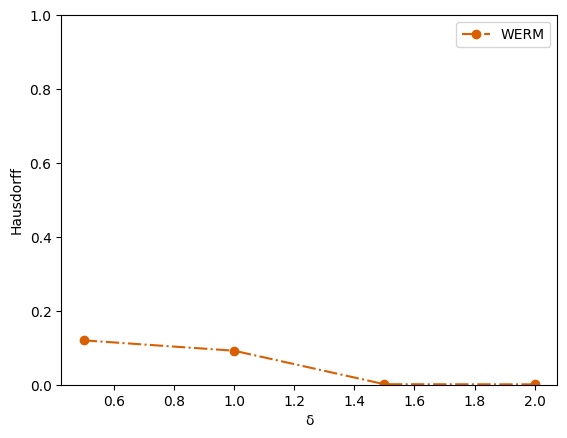

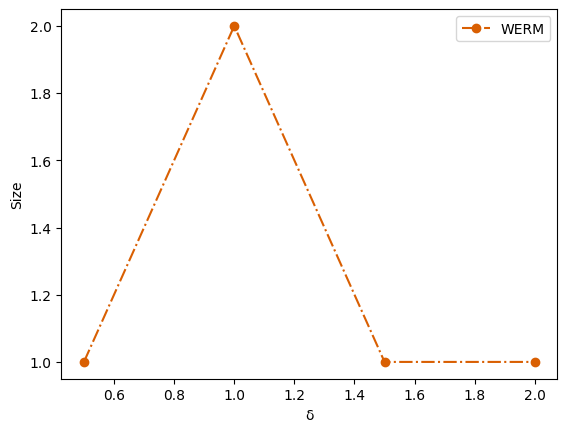

In [6]:
# Hausdorff plots
plt.errorbar(δ_list, WERM_haus_list, label="WERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
# plt.errorbar(δ_list, NWERM_haus_list, label="NWERM", marker="o", ls="--", c=PAL[2], alpha = 1.0)
# plt.errorbar(δ_list, DCDP_haus_list, label="DCDP", marker="o", ls="-.", c=PAL[3], alpha = 1.0)
# plt.errorbar(δ_list, AMP_haus_list, label="AMP", marker="o", ls="--", c=PAL[0], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_sigma" + str(σ) + ".pdf")
plt.show()

# size plots
plt.errorbar(δ_list, WERM_size_list, label="WERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
# plt.errorbar(δ_list, NWERM_haus_list, label="NWERM", marker="o", ls="--", c=PAL[2], alpha = 1.0)
# plt.errorbar(δ_list, DCDP_haus_list, label="DCDP", marker="o", ls="-.", c=PAL[3], alpha = 1.0)
# plt.errorbar(δ_list, AMP_haus_list, label="AMP", marker="o", ls="--", c=PAL[0], alpha = 1.0)
# plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_sigma" + str(σ) + ".pdf")
plt.show()

# Save variables using numpy save
# np.save("figures/WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_sigma" + str(σ) + "_lasso_corr_list", lasso_corr_list)
# np.save("figures/WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_sigma" + str(σ) + "_WERM_haus_list", WERM_haus_list)
# np.save("figures/WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_sigma" + str(σ) + "_WERM_size_list", WERM_size_list)


FileNotFoundError: [Errno 2] No such file or directory: 'figures/marginal_display.pdf'

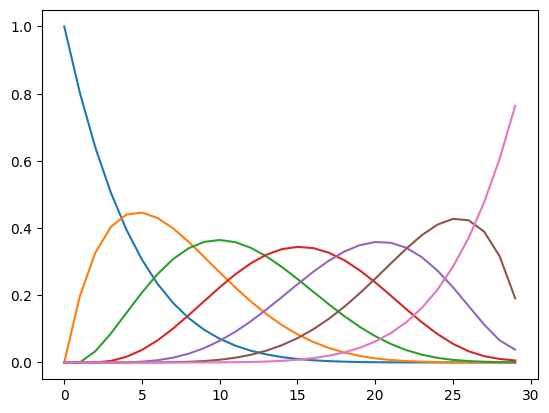

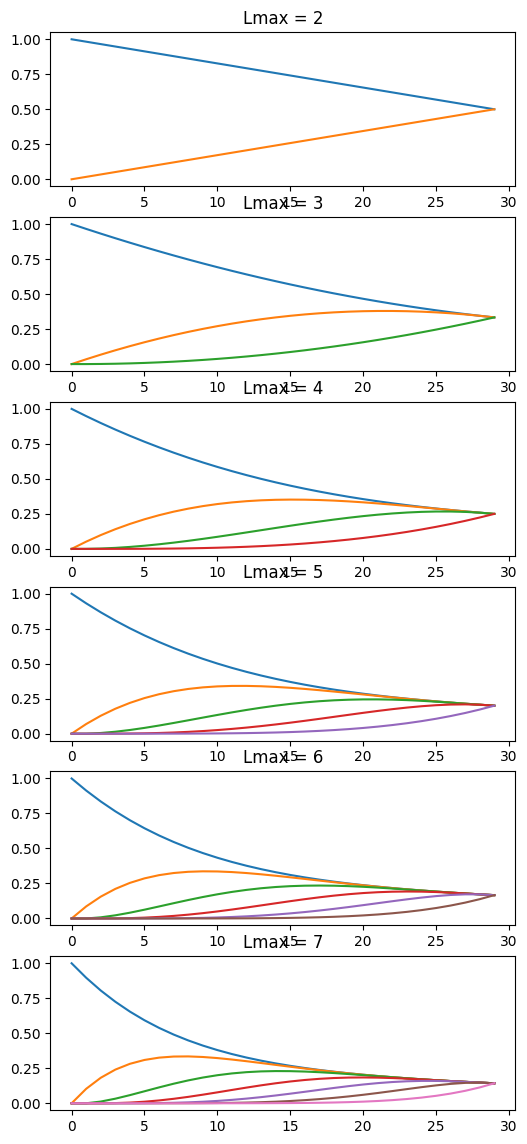

In [3]:
n_ = 30

Δ_ = lambda n_: int(n_/30)

Lmin_ = 1
Lmax_ = 7
a_, η_arr_, p_η_arr_, ϕ_ = unif_prior_to_η_ϕ(Lmin_, Lmax_, Δ_(n_), n_) # Lxn matrix

plt.plot(ϕ_.T)

# Iterate over Lmax_ and make each one a subplot
fig, axs = plt.subplots(6, 1, figsize=(6, 14))
for Lmax_ in range(2, 8):
    p_l = 1/Lmax_ * np.ones(Lmax_) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    # p_l = None
    a_, η_arr_, p_η_arr_, ϕ_ = unif_prior_to_η_ϕ(Lmin_, Lmax_, Δ_(n_), n_, p_l = p_l) # Lxn matrix
    axs[Lmax_-2].plot(ϕ_.T)
    axs[Lmax_-2].set_title(f"Lmax = {Lmax_}")

# fig.savefig("figures/marginal_display.pdf")
fig.show()


# Logistic Reg + Covariance

In [1]:
def ζ(z):
    return jnp.log(1 + jnp.exp(z))

def ζ_prime(z):
    return jnp.power(1 + jnp.exp(-z), -1 * np.ones(z.shape))

# def LR_j_sample(Θ, c_j, L):
#     """Logistic regression with a changepoint, output at index j. Sample output yj according to signal index cj. θ=XB.
#     Tested."""
#     if Θ.ndim == 1:
#         Θ = Θ.reshape((1, L))
#     num_samples = Θ.shape[0]
#     # η = jnp.array(nprandom.normal(loc=0, scale=σ, size=(num_samples, 1))) # noise
#     # Sample uniform noise from 0 to 1
#     η = jnp.array(nprandom.uniform(size=(num_samples, 1)))
#     Ψ = jnp.zeros((num_samples, L))
#     Ψ = Ψ.at[:, c_j].set(1)

#     # print("eval: ", ζ_prime(jnp.multiply(Θ, (Ψ == 1).astype(int)).sum(axis=1).reshape(
#     #     (num_samples, 1))))
#     # print("noise: ", η)
#     Y = jnp.greater(ζ_prime(jnp.multiply(Θ, (Ψ == 1).astype(int)).sum(axis=1).reshape(
#         (num_samples, 1))), η).astype(int)
#     return Y

# def LR(Θ, C):
#     """ Logistic Regression with a Change Point. This takes in Θ ∈ R^{nxL} and C ∈ {0,L-1}^{nxL} and returns Y ∈ R^{nx1}.
#     Needs to be differentiable to go into SE_fixed_C.  """

#     L = Θ.shape[1]
#     return jax.vmap(LR_j_sample, in_axes=(0, 0, None), \
#                     out_axes=0)(Θ, C, L).reshape((Θ.shape[0], 1))

def LR_j_sample(Θ, c_j, η_j, L):
    """Logistic regression with a changepoint, output at index j. Sample output yj according to signal index cj. θ=XB.
    Tested."""
    if Θ.ndim == 1:
        Θ = Θ.reshape((1, L))
    num_samples = Θ.shape[0]
    # η = jnp.array(nprandom.normal(loc=0, scale=σ, size=(num_samples, 1))) # noise
    # Sample uniform noise from 0 to 1
    # η = jnp.array(nprandom.uniform(size=(num_samples, 1)))
    
    η = jnp.array(η_j.reshape((num_samples, 1)))
    Ψ = jnp.zeros((num_samples, L))
    Ψ = Ψ.at[:, c_j].set(1)

    # print("eval: ", ζ_prime(jnp.multiply(Θ, (Ψ == 1).astype(int)).sum(axis=1).reshape(
    #     (num_samples, 1))))
    # print("noise: ", η)
    Y = jnp.greater(ζ_prime(jnp.multiply(Θ, (Ψ == 1).astype(int)).sum(axis=1).reshape(
        (num_samples, 1))), η).astype(int)
    return Y

def LR(Θ, C):
    """ Logistic Regression with a Change Point. This takes in Θ ∈ R^{nxL} and C ∈ {0,L-1}^{nxL} and returns Y ∈ R^{nx1}.
    Needs to be differentiable to go into SE_fixed_C.  """

    L = Θ.shape[1]
    η = jnp.array(nprandom.uniform(size=(Θ.shape[0], 1)))
    return jax.vmap(LR_j_sample, in_axes=(0, 0, 0, None), \
                    out_axes=0)(Θ, C, η, L).reshape((Θ.shape[0], 1))

def LR_gof_j(Θ, y, c_j, L):
    if Θ.ndim == 1:
        Θ = Θ.reshape((1, L))
    num_samples = Θ.shape[0]
    Ψ = jnp.zeros((num_samples, L))
    Ψ = Ψ.at[:, c_j].set(1)

    Z_ψ = jnp.multiply(Θ, (Ψ == 1).astype(int)).sum(axis=1).reshape(
        (num_samples, 1)) # Trick that allows jax to differentiate through, turns indexing into multiplication
    gof_j = ζ(Z_ψ) - jnp.multiply(y, Z_ψ)
    return gof_j

def LR_gof_i(Θ, y, C):
    """ Logistic Regression with a Change Point. This takes in Θ ∈ R^{nxL} and C ∈ {0,L-1}^{nxL} and returns Y ∈ R^{nx1}.  """

    L = Θ.shape[1]
    n = Θ.shape[0]
    if C.shape != (n, 1):
        C = C.reshape((n, 1))
    gof_vec = jax.vmap(LR_gof_j, in_axes=(0, 0, 0, None), \
                    out_axes=0)(Θ, y, C, L)
    return gof_vec.sum() / y.shape[0]

def LR_chgpt_gof_jax(Θ, y, η_arr):

    C_s = amp.posterior.η_arr_to_C_s(η_arr, Θ.shape[0])  

    gof = jax.vmap(LR_gof_i, in_axes=(None, None, 0), out_axes=0)(Θ, y, C_s)
    idx_opt = jnp.argmin(gof)
    η_opt = η_arr[idx_opt]
    return η_opt[η_opt != -1], idx_opt

def LR_plot_gof_jax(Θ, y, η_arr):
    C_s = amp.posterior.η_arr_to_C_s(η_arr, Θ.shape[0])  

    gof = jax.vmap(LR_gof_i, in_axes=(None, None, 0), out_axes=0)(Θ, y, C_s)
    fig, ax = plt.subplots()
    ax.plot(gof)
    return fig

def LR_plot_gof(Θ, y, η_arr):
    C_s = amp.posterior.η_arr_to_C_s(η_arr, Θ.shape[0])  

    gof = np.zeros(len(C_s))
    for i in range(len(C_s)): 
        ψ = C_s[i]
        gof[i] = (ζ(Θ[np.arange(Θ.shape[0]), ψ]) - np.multiply(y, Θ[np.arange(Θ.shape[0]), ψ])).sum() / y.shape[0]
    fig, ax = plt.subplots()
    ax.plot(gof)
    return fig

def LR_chgpt_gof(Z, y, η_arr):
    """ Z is n × L, where L is the number of signals. Inefficient for now. """

    C_s = amp.posterior.η_arr_to_C_s(η_arr, Z.shape[0])  

    m = np.inf
    for i in range(len(C_s)): 
        ψ = C_s[i]
        # gof = np.linalg.norm(y - Z[np.arange(Z.shape[0]), ψ], ord=2)**2 / y.shape[0]
        gof = (ζ(Z[np.arange(Z.shape[0]), ψ]) - np.multiply(y, Z[np.arange(Z.shape[0]), ψ])).sum() / y.shape[0]
        if gof < m:
            m = gof
            η_opt = η_arr[i]
            i_opt = i
    return η_opt[η_opt != -1], i_opt

  0%|          | 0/5 [00:00<?, ?it/s]

δ =  2.0
True chgpts = [500]
fraction of ones:  0.509
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


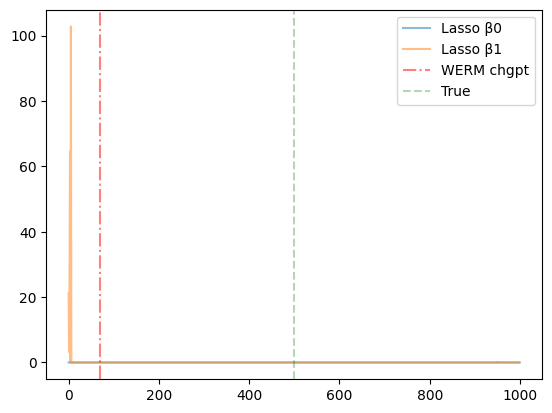

 20%|██        | 1/5 [00:03<00:14,  3.64s/it]

δ =  2.5
True chgpts = [625]
fraction of ones:  0.4672
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


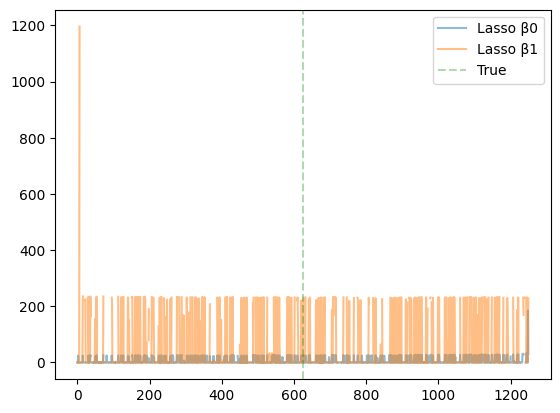

 40%|████      | 2/5 [00:11<00:18,  6.10s/it]

δ =  3.0
True chgpts = [750]
fraction of ones:  0.49466666666666664
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


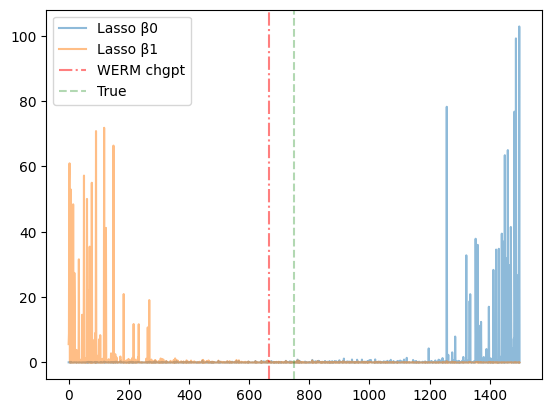

 60%|██████    | 3/5 [00:17<00:11,  5.90s/it]

δ =  3.5
True chgpts = [875]
fraction of ones:  0.5085714285714286
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


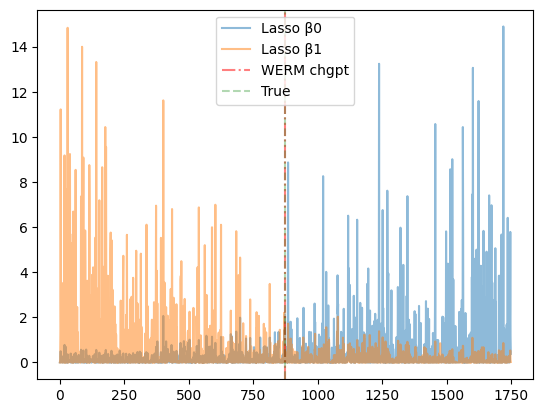

 80%|████████  | 4/5 [00:21<00:05,  5.39s/it]

δ =  4.0
True chgpts = [1000]
fraction of ones:  0.513
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


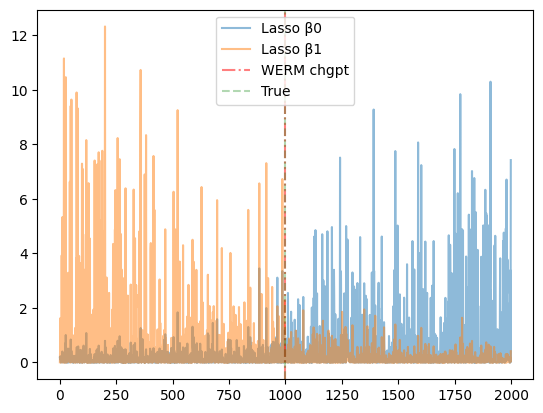

100%|██████████| 5/5 [00:26<00:00,  5.27s/it]


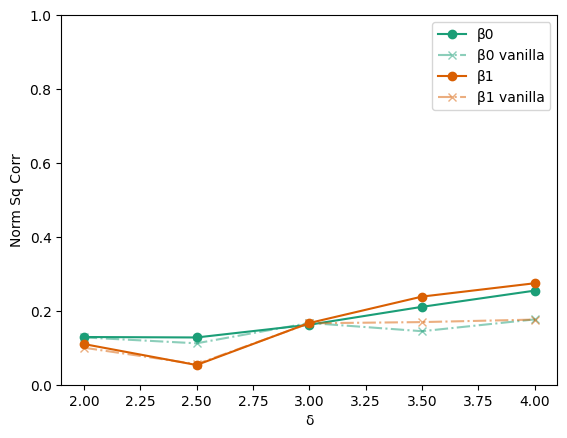

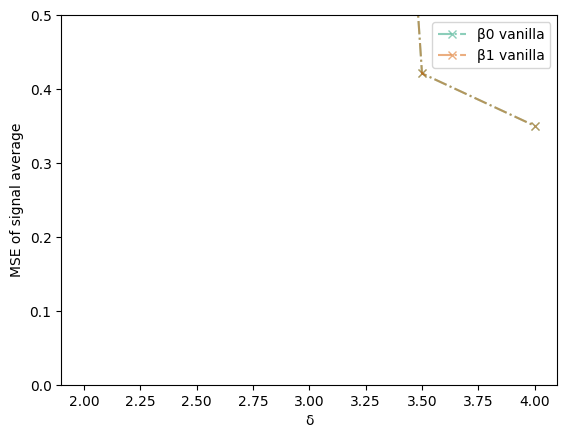

In [2]:
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from amp import MSE, MSE_normalized, norm_sq_corr, PAL, hausdorff
from amp.marginal_separable_jax import q, GAMP_full, SE_fixed_C_v1, GAMP_gaussian_clean, SE_fixed_C, GAMP
import amp.marginal_separable_jax
import amp.changepoint_jax as changepoint_jax
import amp.signal_configuration
from amp.signal_configuration import C_to_chgpt, generate_C_distanced, unif_prior_to_η_ϕ
from amp.signal_priors import SignalPrior, SparseDiffSignal, SparseGaussianSignal, GaussianSignal
from amp.posterior import MAP, MAP_η, compute_posterior, posterior_over_η, η_to_ψ
from amp.marginal_separable_jax import GAMP_gaussian_clean, GAMP_real_data, q
from amp.signal_priors import GaussianSignal
import amp.comparison
from functools import partial
from tqdm import tqdm
import scipy
tqdm = partial(tqdm, position=0, leave=True)
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
import scipy

# Remove sklearn warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

# np.random.seed(1)

p = 500
L = 2 # num signals. L-1 changepoints

δ_list = [2.0, 2.5, 3.0, 3.5, 4.0]

# chgpt_locations = np.array([0.3, 0.7])
chgpt_locations = np.array([0.5])

### Define a function that finds the optimal changepoint location given z = Xβ and y
def opt_chgpt_gof(Z, y, η_arr):
    """ Z is n × L, where L is the number of signals. """

    C_s = amp.posterior.η_arr_to_C_s(η_arr, Z.shape[0])  

    m = np.inf
    for i in range(len(C_s)): 
        ψ = C_s[i]
        gof = np.linalg.norm(y - Z[np.arange(Z.shape[0]), ψ], ord=2)**2 / y.shape[0]
        if gof < m:
            m = gof
            η_opt = η_arr[i]
            i_opt = i
    return η_opt[η_opt != -1], i_opt

corr_1_list = []
corr_2_list = []
corr_1_SE_list = []
corr_2_SE_list = []
post_list = []
WERM_haus_list = []
WERM_size_list = []
NWERM_haus_list = []
DCDP_haus_list = []
AMP_haus_list = []
lasso_corr_list = [[] for ℓ in range(L)]
lasso_vanilla_corr_list = [[] for ℓ in range(L)]
vanilla_mse_signal_avg_list = [[] for ℓ in range(L)]

# Generate a covariance matrix
# Identity covariance
# Σ = np.eye(p)
# Generate a reasonable covariance matrix
Σ = np.zeros((p, p))
for i in range(p):
    for j in range(p):
        Σ[i, j] = 0.5 ** (np.abs(i - j))
# Another random covariance construction: 
# A_ = np.random.rand(p, p)
# Σ = np.dot(A_, A_.transpose()) / p

L_chol = scipy.linalg.cholesky(Σ, lower = True)

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    true_chgpt_locations = lambda n: (n*chgpt_locations).astype(int)

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 1
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    print(f"True chgpts = {true_chgpt_locations(n)}")
    C_true = η_to_ψ(true_chgpt_locations(n), n)

    # Samples a sparse gaussian vector
    # σ_l_arr = 1.0 * np.ones(L) # signal standard deviation
    # α = 0.5 # fraction of nonzeros
    # signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # Gaussian Signal Prior
    κ = 7.0
    # B̃_cov = κ**2 * np.eye(L) # Helps to keep the signal variance small, to avoid the phase transition of Candes
    base_cov = np.eye(L)
    # base_cov[0, 1] = -0.99
    # base_cov[1, 0] = -0.99
    B̃_cov = κ**2 * δ * base_cov # This technically keeps the signal power fixed, this seems important for estimating size. 
    # κ = 1.0
    # B̃_cov = (κ**2 / n) * np.eye(L) # Scaled so that, with unit design we have 
    # B̃_cov = (κ**2 / n) * np.eye(L) # Scaled so that, with unit design we have 
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T
    # X = np.random.normal(0, 1, (n, p)) @ L_chol.T

    # scaler = StandardScaler().fit(X)
    # X = scaler.transform(X)
    Θ = X @ B̃
    Y = LR(Θ, C_true)
    print("fraction of ones: ", Y.sum() / n)

    # --- Run Weighted ERM --- #

    B̂ = np.zeros((p, L))
    for ℓ in range(L):
        print("Regressing on signal ", ℓ)
        sample_weight = ϕ[ℓ, :]
        # Weight data for \beta^1, ϕ is L × n
        # logistic_reg_CV = linear_model.LogisticRegressionCV(cv=5, n_jobs = 2, penalty = 'l2', max_iter=int(1e5))
        # logistic_reg_CV.fit(X, Y.flatten(), sample_weight = sample_weight)
        # print("C_: ", logistic_reg_CV.C_)
        # logistic_reg = linear_model.LogisticRegression(C=logistic_reg_CV.C_[0], n_jobs = 2, penalty = 'l2', max_iter=int(1e5))
        logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5), penalty = None)
        logistic_reg.fit(X, Y, sample_weight = sample_weight)
        β̂ = logistic_reg.coef_
        B̂[:, ℓ] = β̂
        lasso_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))

    # --- Run Vanilla ERM for comparison --- #
    print("Regressing with vanilla ERM for comparison")
    logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5), penalty = None)
    logistic_reg.fit(X, Y)
    β̂ = logistic_reg.coef_
    avg_of_signals = np.mean(B̃, axis=1)
    for ℓ in range(L):
        lasso_vanilla_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))
        vanilla_mse_signal_avg_list[ℓ].append(MSE(β̂, avg_of_signals) / (κ**2 * δ))
    

    ## Compute MAP estimate for WERM
    for ℓ in range(L):
        plt.plot(np.arange(n), (ζ(X @ B̂[:, ℓ]) - np.multiply(Y.flatten(), X @ B̂[:, ℓ])), alpha = 0.5, label="Lasso β" + str(ℓ))
        # plt.plot(((Y.flatten() - X @ B̂[:, ℓ])**2), alpha = 0.5, label="Lasso β" + str(ℓ))
    Z = X @ B̂
    print("Computing GOF: ")
    opt_chgpt_loc, opt_chgpt_idx = LR_chgpt_gof_jax(Z, Y.flatten(), η_arr)
    # plot a vertical line at the optimal changepoint location
    [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.5, label="WERM chgpt") for loc in opt_chgpt_loc]
    [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.3, label="True") for c in true_chgpt_locations(n)]
    WERM_haus_list.append(1/n * hausdorff(opt_chgpt_loc, true_chgpt_locations(n)))
    WERM_size_list.append(len(opt_chgpt_loc[opt_chgpt_loc != -1]))
    print("Plotting GOF: ")
    # fig = LR_plot_gof_jax(Z, Y.flatten(), η_arr)
    # fig.show()
    # fig = LR_plot_gof(Z, Y.flatten(), η_arr)
    # fig.show()

    plt.legend()
    plt.show()


# Sqcorr plots
for ℓ in range(L):
    plt.errorbar(δ_list, lasso_corr_list[ℓ], label="β" + str(ℓ), marker="o", ls="-", c=PAL[ℓ], alpha = 1.0)
    plt.errorbar(δ_list, lasso_vanilla_corr_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# Plot the MSE of the signal average
for ℓ in range(L):
    plt.errorbar(δ_list, vanilla_mse_signal_avg_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.xlabel("δ")
plt.ylim(0, 0.5)
plt.ylabel("MSE of signal average")
plt.legend()
plt.show()


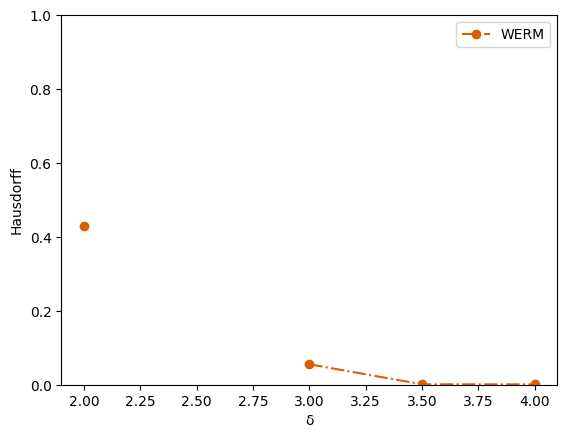

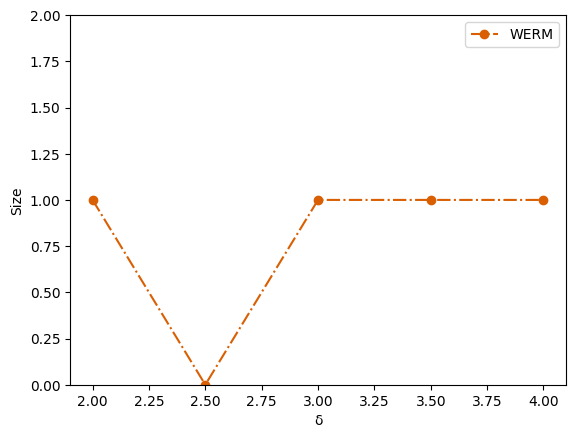

In [3]:
# Hausdorff plots
plt.errorbar(δ_list, WERM_haus_list, label="WERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Save variables using numpy save
# np.save("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0])  + "_lasso_corr_list", lasso_corr_list)
# np.save("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_WERM_haus_list", WERM_haus_list)
# np.save("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_WERM_size_list", WERM_size_list)

# Size plots
plt.errorbar(δ_list, WERM_size_list, label="WERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.ylim((0, L))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_size.pdf")
plt.show()



# Logistic plot vs. chgpt location

  0%|          | 0/9 [00:00<?, ?it/s]

chgpt loc =  0.1
True chgpts = [112]
fraction of ones:  0.488
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


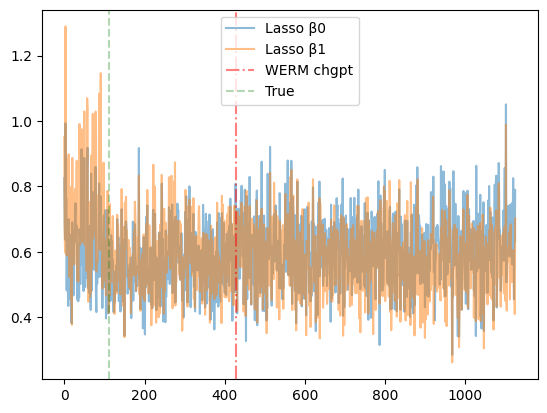

 11%|█         | 1/9 [00:03<00:29,  3.73s/it]

chgpt loc =  0.2
True chgpts = [225]
fraction of ones:  0.49866666666666665
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


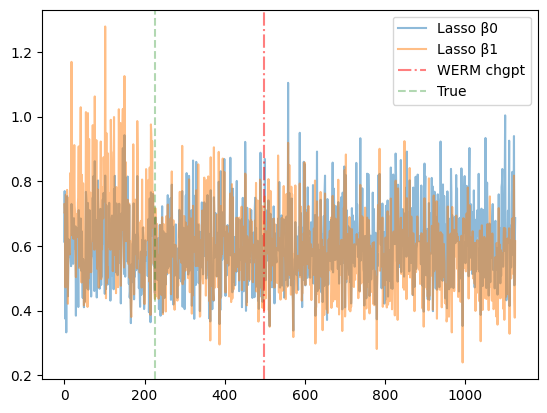

 22%|██▏       | 2/9 [00:07<00:25,  3.63s/it]

chgpt loc =  0.3
True chgpts = [337]
fraction of ones:  0.5253333333333333
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


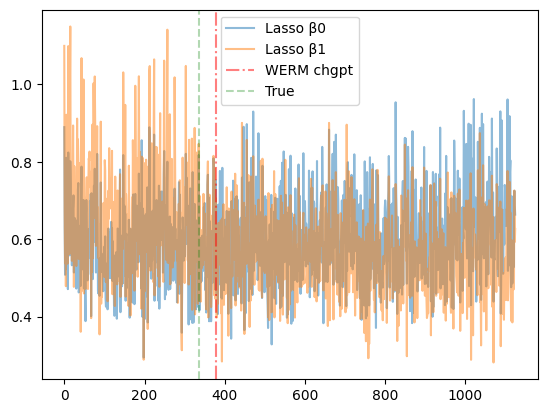

 33%|███▎      | 3/9 [00:10<00:21,  3.64s/it]

chgpt loc =  0.4
True chgpts = [450]
fraction of ones:  0.49777777777777776
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


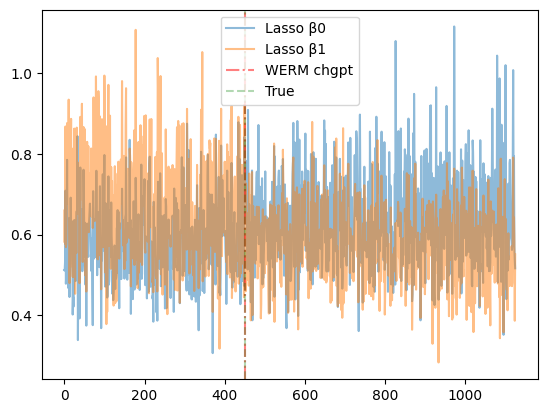

 44%|████▍     | 4/9 [00:14<00:18,  3.64s/it]

chgpt loc =  0.5
True chgpts = [562]
fraction of ones:  0.49422222222222223
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


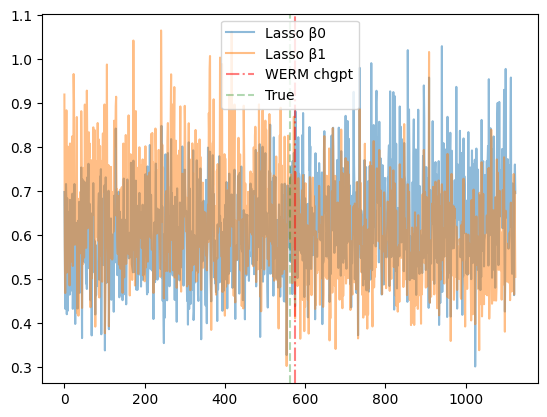

 56%|█████▌    | 5/9 [00:18<00:14,  3.64s/it]

chgpt loc =  0.6
True chgpts = [675]
fraction of ones:  0.4862222222222222
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


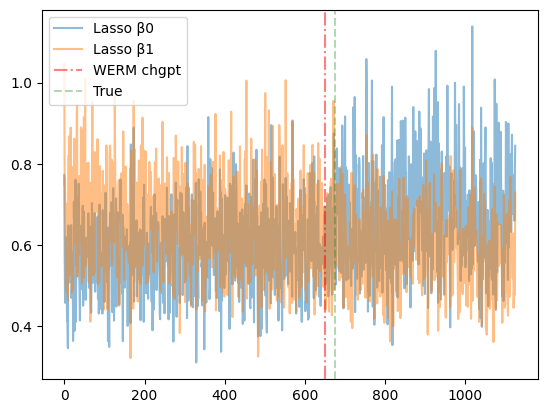

 67%|██████▋   | 6/9 [00:21<00:10,  3.66s/it]

chgpt loc =  0.7
True chgpts = [787]
fraction of ones:  0.49777777777777776
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


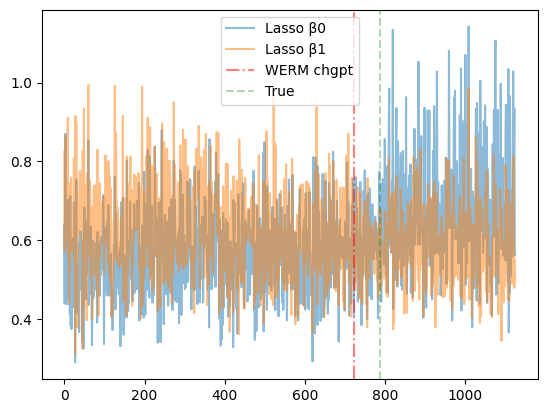

 78%|███████▊  | 7/9 [00:25<00:07,  3.66s/it]

chgpt loc =  0.8
True chgpts = [900]
fraction of ones:  0.48977777777777776
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


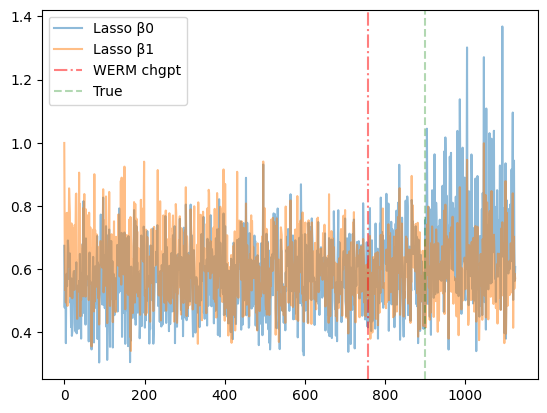

 89%|████████▉ | 8/9 [00:29<00:03,  3.65s/it]

chgpt loc =  0.9
True chgpts = [1012]
fraction of ones:  0.46755555555555556
Regressing on signal  0
Regressing on signal  1
Regressing with vanilla ERM for comparison
Computing GOF: 
Plotting GOF: 


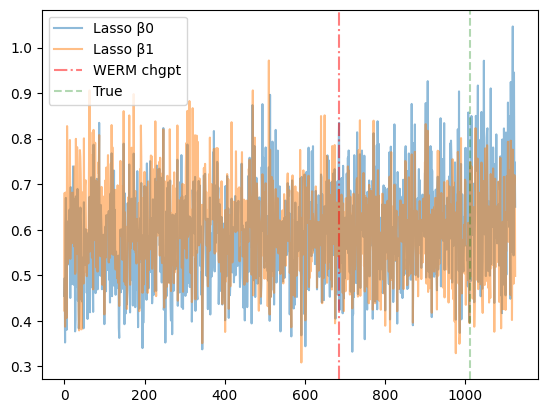

100%|██████████| 9/9 [00:32<00:00,  3.66s/it]


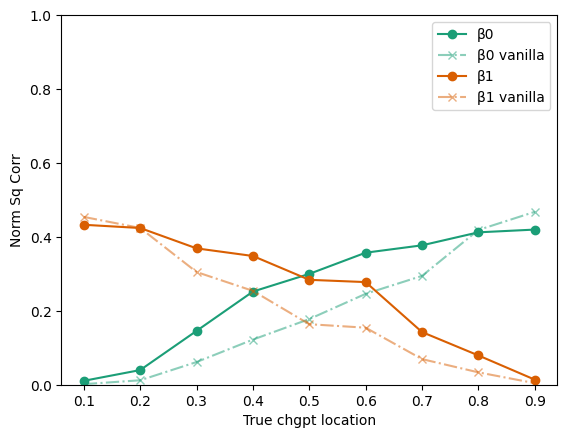

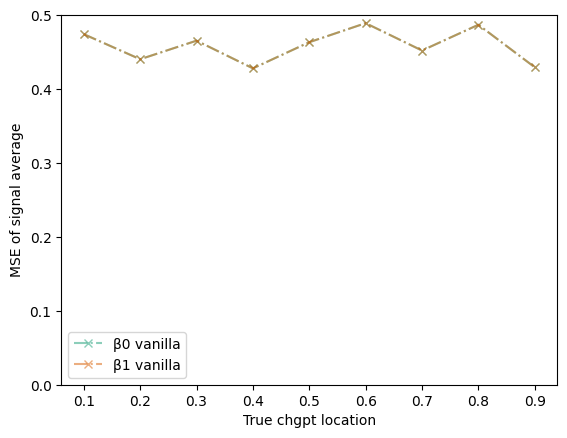

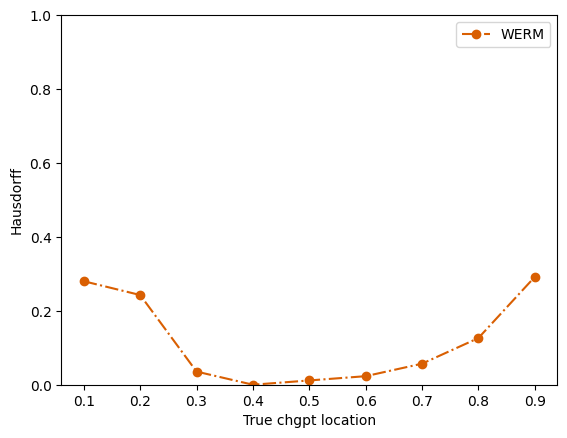

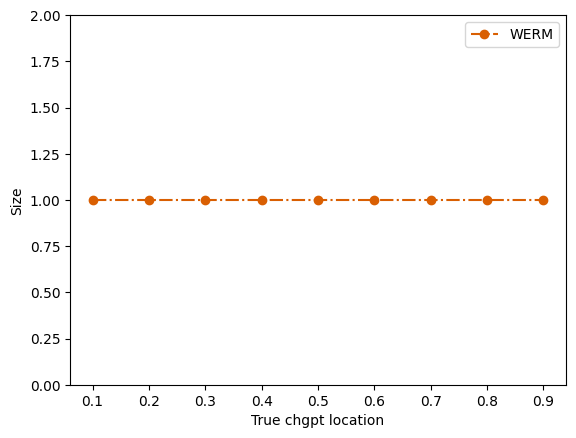

In [6]:
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from amp import MSE, MSE_normalized, norm_sq_corr, PAL, hausdorff
from amp.marginal_separable_jax import q, GAMP_full, SE_fixed_C_v1, GAMP_gaussian_clean, SE_fixed_C, GAMP
import amp.marginal_separable_jax
import amp.changepoint_jax as changepoint_jax
import amp.signal_configuration
from amp.signal_configuration import C_to_chgpt, generate_C_distanced, unif_prior_to_η_ϕ
from amp.signal_priors import SignalPrior, SparseDiffSignal, SparseGaussianSignal, GaussianSignal
from amp.posterior import MAP, MAP_η, compute_posterior, posterior_over_η, η_to_ψ
from amp.marginal_separable_jax import GAMP_gaussian_clean, GAMP_real_data, q
from amp.signal_priors import GaussianSignal
import amp.comparison
from functools import partial
from tqdm import tqdm
import scipy
tqdm = partial(tqdm, position=0, leave=True)
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn import linear_model
from sklearn.preprocessing import StandardScaler
import scipy

# Remove sklearn warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

# np.random.seed(1)

p = 500
L = 2 # num signals. L-1 changepoints

δ_list = [2.25]

# chgpt_locations = np.array([0.3, 0.7])
chgpt_locations_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

### Define a function that finds the optimal changepoint location given z = Xβ and y
def opt_chgpt_gof(Z, y, η_arr):
    """ Z is n × L, where L is the number of signals. """

    C_s = amp.posterior.η_arr_to_C_s(η_arr, Z.shape[0])  

    m = np.inf
    for i in range(len(C_s)): 
        ψ = C_s[i]
        gof = np.linalg.norm(y - Z[np.arange(Z.shape[0]), ψ], ord=2)**2 / y.shape[0]
        if gof < m:
            m = gof
            η_opt = η_arr[i]
            i_opt = i
    return η_opt[η_opt != -1], i_opt

corr_1_list = []
corr_2_list = []
corr_1_SE_list = []
corr_2_SE_list = []
post_list = []
WERM_haus_list = []
WERM_size_list = []
NWERM_haus_list = []
DCDP_haus_list = []
AMP_haus_list = []
lasso_corr_list = [[] for ℓ in range(L)]
lasso_vanilla_corr_list = [[] for ℓ in range(L)]
vanilla_mse_signal_avg_list = [[] for ℓ in range(L)]

# Generate a covariance matrix
# Identity covariance
# Σ = np.eye(p)
# Generate a reasonable covariance matrix
Σ = np.zeros((p, p))
for i in range(p):
    for j in range(p):
        Σ[i, j] = 0.5 ** (np.abs(i - j))
# Another random covariance construction: 
# A_ = np.random.rand(p, p)
# Σ = np.dot(A_, A_.transpose()) / p

L_chol = scipy.linalg.cholesky(Σ, lower = True)

for i in tqdm(range(len(chgpt_locations_list))):
    δ = 2.25
    print("chgpt loc = ", chgpt_locations_list[i])
    chgpt_locations = np.array([chgpt_locations_list[i]])

    n = int(δ * p)
    true_chgpt_locations = lambda n: (n*chgpt_locations).astype(int)

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 1
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    print(f"True chgpts = {true_chgpt_locations(n)}")
    C_true = η_to_ψ(true_chgpt_locations(n), n)

    # Samples a sparse gaussian vector
    # σ_l_arr = 1.0 * np.ones(L) # signal standard deviation
    # α = 0.5 # fraction of nonzeros
    # signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    # Gaussian Signal Prior
    κ = 7.0
    # B̃_cov = κ**2 * np.eye(L) # Helps to keep the signal variance small, to avoid the phase transition of Candes
    base_cov = np.eye(L)
    # base_cov[0, 1] = 0.5
    # base_cov[1, 0] = 0.5
    B̃_cov = κ**2 * δ * base_cov # This technically keeps the signal power fixed, this seems important for estimating size. 
    # κ = 1.0
    # B̃_cov = (κ**2 / n) * np.eye(L) # Scaled so that, with unit design we have 
    # B̃_cov = (κ**2 / n) * np.eye(L) # Scaled so that, with unit design we have 
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = signal_prior.sample(p)

    # Generate the observation vector Y
    X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T
    # X = np.random.normal(0, 1, (n, p)) @ L_chol.T

    # scaler = StandardScaler().fit(X)
    # X = scaler.transform(X)
    Θ = X @ B̃
    Y = LR(Θ, C_true)
    print("fraction of ones: ", Y.sum() / n)

    # --- Run Weighted ERM --- #

    B̂ = np.zeros((p, L))
    for ℓ in range(L):
        print("Regressing on signal ", ℓ)
        sample_weight = ϕ[ℓ, :]
        # Weight data for \beta^1, ϕ is L × n
        # logistic_reg_CV = linear_model.LogisticRegressionCV(cv=5, n_jobs = 2, penalty = 'l2', max_iter=int(1e5))
        # logistic_reg_CV.fit(X, Y.flatten(), sample_weight = sample_weight)
        # print("C_: ", logistic_reg_CV.C_)
        # logistic_reg = linear_model.LogisticRegression(C=logistic_reg_CV.C_[0], n_jobs = 2, penalty = 'l2', max_iter=int(1e5))
        logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5))
        logistic_reg.fit(X, Y, sample_weight = sample_weight)
        β̂ = logistic_reg.coef_
        B̂[:, ℓ] = β̂
        lasso_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))

    # --- Run Vanilla ERM for comparison --- #
    print("Regressing with vanilla ERM for comparison")
    logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5))
    logistic_reg.fit(X, Y)
    β̂ = logistic_reg.coef_
    avg_of_signals = np.mean(B̃, axis=1)
    for ℓ in range(L):
        lasso_vanilla_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))
        vanilla_mse_signal_avg_list[ℓ].append(MSE(β̂, avg_of_signals) / (κ**2 * δ))
    

    ## Compute MAP estimate for WERM
    for ℓ in range(L):
        plt.plot(np.arange(n), (ζ(X @ B̂[:, ℓ]) - np.multiply(Y.flatten(), X @ B̂[:, ℓ])), alpha = 0.5, label="Lasso β" + str(ℓ))
        # plt.plot(((Y.flatten() - X @ B̂[:, ℓ])**2), alpha = 0.5, label="Lasso β" + str(ℓ))
    Z = X @ B̂
    print("Computing GOF: ")
    opt_chgpt_loc, opt_chgpt_idx = LR_chgpt_gof_jax(Z, Y.flatten(), η_arr)
    # plot a vertical line at the optimal changepoint location
    [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.5, label="WERM chgpt") for loc in opt_chgpt_loc]
    [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.3, label="True") for c in true_chgpt_locations(n)]
    WERM_haus_list.append(1/n * hausdorff(opt_chgpt_loc, true_chgpt_locations(n)))
    WERM_size_list.append(len(opt_chgpt_loc[opt_chgpt_loc != -1]))
    print("Plotting GOF: ")
    # fig = LR_plot_gof_jax(Z, Y.flatten(), η_arr)
    # fig.show()
    # fig = LR_plot_gof(Z, Y.flatten(), η_arr)
    # fig.show()

    plt.legend()
    plt.show()


# Sqcorr plots
for ℓ in range(L):
    plt.errorbar(chgpt_locations_list, lasso_corr_list[ℓ], label="β" + str(ℓ), marker="o", ls="-", c=PAL[ℓ], alpha = 1.0)
    plt.errorbar(chgpt_locations_list, lasso_vanilla_corr_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("True chgpt location")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# Plot the MSE of the signal average
for ℓ in range(L):
    plt.errorbar(chgpt_locations_list, vanilla_mse_signal_avg_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.xlabel("True chgpt location")
plt.ylim(0, 0.5)
plt.ylabel("MSE of signal average")
plt.legend()
plt.show()

# Hausdorff plots
plt.errorbar(chgpt_locations_list, WERM_haus_list, label="WERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.ylim((0, 1))
plt.xlabel("True chgpt location")
plt.ylabel("Hausdorff")
plt.legend()
plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Save variables using numpy save
# np.save("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0])  + "_lasso_corr_list", lasso_corr_list)
np.save("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_WERM_haus_list", WERM_haus_list)
np.save("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_WERM_size_list", WERM_size_list)

# Size plots
plt.errorbar(chgpt_locations_list, WERM_size_list, label="WERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.ylim((0, L))
plt.xlabel("True chgpt location")
plt.ylabel("Size")
plt.legend()
plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + "_size.pdf")
plt.show()

# Try WERM for MLR

  0%|          | 0/4 [00:00<?, ?it/s]

δ =  0.5
Regressing on signal  0
Regressing on signal  1


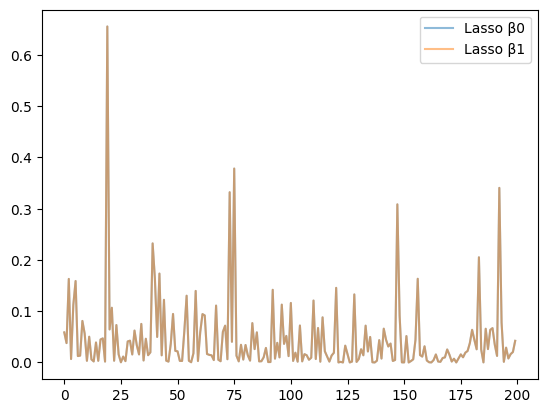

Regressing with vanilla ERM for comparison


 25%|██▌       | 1/4 [00:29<01:27, 29.26s/it]

δ =  1.0
Regressing on signal  0
Regressing on signal  1


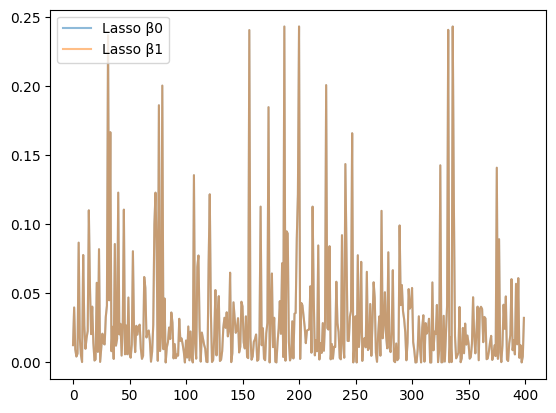

Regressing with vanilla ERM for comparison


 50%|█████     | 2/4 [02:16<02:30, 75.29s/it]

δ =  1.5
Regressing on signal  0
Regressing on signal  1


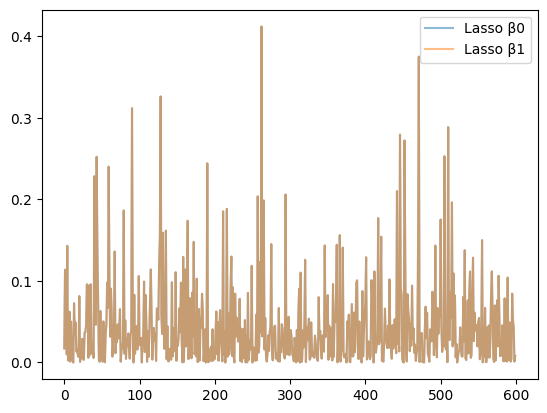

Regressing with vanilla ERM for comparison


 75%|███████▌  | 3/4 [02:25<00:45, 45.06s/it]

δ =  2.0
Regressing on signal  0
Regressing on signal  1


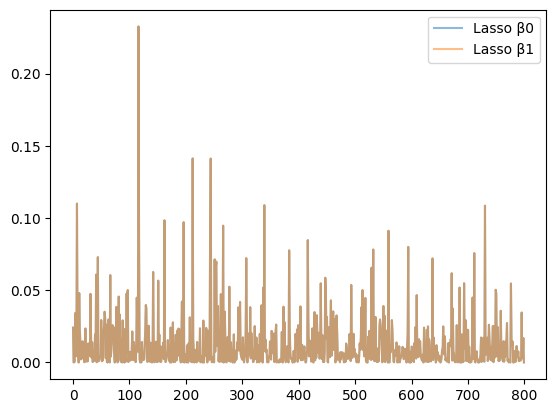

Regressing with vanilla ERM for comparison


100%|██████████| 4/4 [02:31<00:00, 37.76s/it]


NameError: name 'chgpt_locations_list' is not defined

In [3]:
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
from amp import MSE, norm_sq_corr, PAL, hausdorff
from amp.marginal_separable_jax import q, GAMP_full, SE_fixed_C_v1, GAMP_gaussian_clean, SE_fixed_C, GAMP
import amp.marginal_separable_jax
import amp.changepoint_jax as changepoint_jax
import amp.signal_configuration
from amp.signal_configuration import C_to_chgpt, generate_C_distanced, unif_prior_to_η_ϕ
from amp.signal_priors import SignalPrior, SparseDiffSignal, SparseGaussianSignal, GaussianSignal
from amp.posterior import MAP, MAP_η, compute_posterior, posterior_over_η, η_to_ψ
from amp.marginal_separable_jax import GAMP_gaussian_clean, GAMP_real_data, q
from amp.signal_priors import GaussianSignal
import amp.comparison
from functools import partial
from tqdm import tqdm
import scipy
tqdm = partial(tqdm, position=0, leave=True)
import numpy as np
import time
import matplotlib.pyplot as plt
from sklearn import linear_model
import scipy

# Remove sklearn warnings
def warn(*args, **kwargs):
    pass
import warnings
warnings.warn = warn

# np.random.seed(1)

p = 400
σ = 0.1 # noise standard deviation
L = 2 # num signals. L-1 changepoints

δ_list = [0.5, 1.0, 1.5, 2.0]

ϕ_mlr = 0.3

### Define a function that finds the optimal changepoint location given z = Xβ and y
def opt_chgpt_gof(Z, y, η_arr):
    """ Z is n × L, where L is the number of signals. """

    C_s = amp.posterior.η_arr_to_C_s(η_arr, Z.shape[0])  

    m = np.inf
    for i in range(len(C_s)): 
        ψ = C_s[i]
        gof = np.linalg.norm(y - Z[np.arange(Z.shape[0]), ψ], ord=2)**2 / y.shape[0]
        if gof < m:
            m = gof
            η_opt = η_arr[i]
            i_opt = i
    return η_opt[η_opt != -1], i_opt

corr_1_list = []
corr_2_list = []
corr_1_SE_list = []
corr_2_SE_list = []
post_list = []
WERM_haus_list = []
WERM_size_list = []
NWERM_haus_list = []
DCDP_haus_list = []
AMP_haus_list = []
lasso_corr_list = [[] for ℓ in range(L)]
lasso_vanilla_corr_list = [[] for ℓ in range(L)]
vanilla_mse_signal_avg_list = [[] for ℓ in range(L)]

# Generate a covariance matrix
# Identity covariance
# Σ = np.eye(p)
# Generate a reasonable covariance matrix
Σ = np.zeros((p, p))
for i in range(p):
    for j in range(p):
        Σ[i, j] = 0.5 ** (np.abs(i - j))
# Another random covariance construction: 
# A_ = np.random.rand(p, p)
# Σ = np.dot(A_, A_.transpose()) / p

L_chol = scipy.linalg.cholesky(Σ, lower = True)

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)

    # --- Preliminaries ---

    # Soft threshold denoiser 
    σ_l_arr = 1.0 * np.ones(L) # signal standard deviation
    α = 0.05 # fraction of nonzeros
    signal_prior = SparseGaussianSignal(α, δ, σ_l_arr)

    B̃ = signal_prior.sample(p)

    # Generate the observation vector Y
    # X = np.random.normal(0, np.sqrt(1/n), (n, p))
    X = np.random.normal(0, np.sqrt(1/n), (n, p)) @ L_chol.T
    Θ = X @ B̃
    C_true = np.random.binomial(1, ϕ_mlr, size=n)
    Y = q(Θ, C_true, σ) 

    ϕ = np.zeros((L, n))
    ϕ[0, :] = ϕ_mlr * np.ones(n)
    ϕ[1, :] = 1 - ϕ[0, :]

    # --- Run Weighted ERM --- #

    B̂ = np.zeros((p, L))
    for ℓ in range(L):
        print("Regressing on signal ", ℓ)
        # Weight data for \beta^1, ϕ is L × n
        Y_weighted = (Y.flatten() * np.sqrt(ϕ[ℓ, :]).flatten()).reshape(-1, 1) # Element-wise multiplication
        X_weighted = X * np.sqrt(ϕ[ℓ, :]).reshape(-1, 1) # Element-wise multiplication
        lasso_cv = linear_model.LassoCV(cv=5, n_jobs=2, tol=1e-5)
        lasso_cv.fit(X_weighted, Y_weighted.flatten())
        lasso = linear_model.Lasso(alpha=lasso_cv.alpha_, tol=1e-12, max_iter=int(1e5))
        lasso.fit(X_weighted, Y_weighted.flatten())
        β̂ = lasso.coef_
        B̂[:, ℓ] = β̂
        lasso_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))

    ## Compute MAP estimate for WERM
    for ℓ in range(L):
        plt.plot(((Y.flatten() - X @ B̂[:, ℓ])**2), alpha = 0.5, label="Lasso β" + str(ℓ))
    # Z = X @ B̂
    # opt_chgpt_loc, opt_chgpt_idx = opt_chgpt_gof(Z, Y.flatten(), η_arr)
    # # plot a vertical line at the optimal changepoint location
    # [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.5, label="WERM chgpt") for loc in opt_chgpt_loc]
    # [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.3, label="True") for c in true_chgpt_locations(n)]
    # WERM_haus_list.append(1/n * hausdorff(opt_chgpt_loc, true_chgpt_locations(n)))
    # WERM_size_list.append(len(opt_chgpt_loc[opt_chgpt_loc != -1]))

    plt.legend()
    plt.show()

    # --- Run Vanilla ERM for comparison --- #
    print("Regressing with vanilla ERM for comparison")
    lasso_cv = linear_model.LassoCV(cv=5, n_jobs=2, tol=1e-5)
    lasso_cv.fit(X, Y.flatten())
    lasso = linear_model.Lasso(alpha=lasso_cv.alpha_, tol=1e-12, max_iter=int(1e5))
    lasso.fit(X, Y)
    β̂ = lasso.coef_
    avg_of_signals = np.mean(B̃, axis=1)
    for ℓ in range(L):
        lasso_vanilla_corr_list[ℓ].append(norm_sq_corr(β̂, B̃[:, ℓ]))
        vanilla_mse_signal_avg_list[ℓ].append(MSE(β̂, avg_of_signals))

# Sqcorr plots
for ℓ in range(L):
    plt.errorbar(δ_list, lasso_corr_list[ℓ], label="β" + str(ℓ), marker="o", ls="-", c=PAL[ℓ], alpha = 1.0)
    plt.errorbar(δ_list, lasso_vanilla_corr_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("True chgpt location")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# Plot the MSE of the signal average
for ℓ in range(L):
    plt.errorbar(δ_list, vanilla_mse_signal_avg_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.xlabel("True chgpt location")
# plt.ylim(0, 0.5)
plt.ylabel("MSE of signal average")
plt.legend()
plt.show()

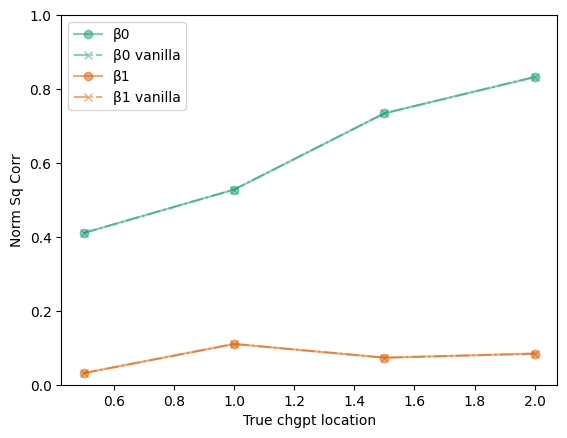

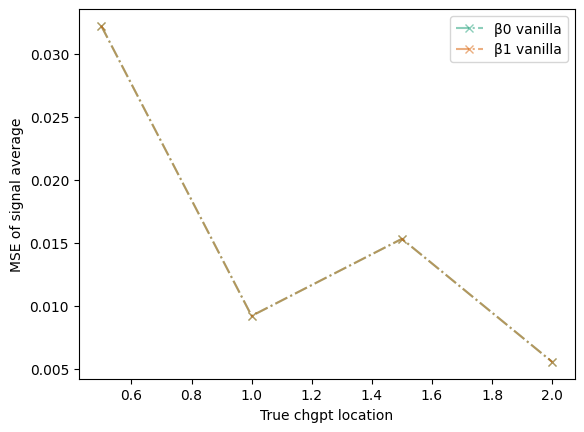

In [5]:
# Sqcorr plots
for ℓ in range(L):
    plt.errorbar(δ_list, lasso_corr_list[ℓ], label="β" + str(ℓ), marker="o", ls="-", c=PAL[ℓ], alpha = 0.5)
    plt.errorbar(δ_list, lasso_vanilla_corr_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("True chgpt location")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# Plot the MSE of the signal average
for ℓ in range(L):
    plt.errorbar(δ_list, vanilla_mse_signal_avg_list[ℓ], label="β" + str(ℓ) + " vanilla", marker="x", ls="-.", c=PAL[ℓ], alpha = 0.5)
plt.xlabel("True chgpt location")
# plt.ylim(0, 0.5)
plt.ylabel("MSE of signal average")
plt.legend()
plt.show()

### WERM does not seem to work well for MLR!